<a href="https://colab.research.google.com/github/alyairawan02/publicdiscussion_analysis/blob/main/Bi_LSTM_dan_SMOTE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install transformers torch

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

# Load model IndoBERT Sentiment Analysis
model_name = "crypter70/IndoBERT-Sentiment-Analysis"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Buat pipeline untuk analisis sentimen
sentiment_pipe = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

In [ ]:
import pandas as pd

# Load file CSV
df = pd.read_excel('hasil_preprocessing_3.xlsx')

df[['normalisasi']].head()

In [ ]:
def get_sentiment(text):
    try:
        result = sentiment_pipe(text)[0]
        label = result['label']
        score = result['score']

        # Mapping label IndoBERT
        mapping = {
            'LABEL_0': 'positive',
            'LABEL_1': 'neutral',
            'LABEL_2': 'negative'
        }

        return mapping.get(label, label), score
    except:
        return None, None

In [ ]:
# Membersihkan kolom 'cleaning' dari NaN atau baris kosong
df = df[df['normalisasi'].notna()]
df = df[df['normalisasi'].str.strip() != '']
df.loc[:, 'normalisasi'] = df['normalisasi'].astype(str)
df = df.reset_index(drop=True)

# Terapkan label sentimen
df['sent_label'], df['sent_score'] = zip(*df['normalisasi'].apply(get_sentiment))

In [ ]:
import pandas as pd

# Terapkan labeling ke seluruh data
df['sent_label'], df['sent_score'] = zip(*df['normalisasi'].apply(get_sentiment))

# Cek hasil awal
df[['normalisasi', 'sent_label', 'sent_score']].head()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# hitung persentase masing-masing sentimen
label_counts = df['sent_label'].value_counts(normalize=True) * 100

# ditampilkan dengan angka
print("Persentase Sentimen:")
print(label_counts.round(2))

# visualisasi pie chart
plt.figure(figsize=(6, 6))
colors = ['#ff9999', '#66b3ff', '#99ff99']  # NEGATIVE, NEUTRAL, POSITIVE
label_counts.plot(kind='pie',
                  autopct='%1.1f%%',
                  colors=colors,
                  startangle=140,
                  shadow=True,
                  explode=(0.03, 0.03, 0.03))

plt.title('Distribusi Sentimen (IndoBERT)')
plt.ylabel('')  # hilangkan label y
plt.tight_layout()
plt.show()

In [ ]:
df.to_excel('hasil_labeling_3.xlsx', index=False)

In [ ]:
import pandas as pd
df = pd.read_excel('hasil_labeling_3.xlsx')

In [ ]:
import random

# Fungsi augmentasi sederhana
def augment_text(text):
    if isinstance(text, str):
        words = text.split()
        if len(words) > 1:
            random.shuffle(words)
        return ' '.join(words)
    return text

In [ ]:
#augmentasi data positif dan negatif

# data awal
df = pd.read_excel('hasil_labeling_3.xlsx')

#Augmentasi POSITIVE
pos_data = df[df['sent_label'].str.upper() == 'POSITIVE']
aug_pos = pos_data.sample(n=2 * len(pos_data), replace=True, random_state=42).copy() #data jadi dua kali lipat lebih banyak
aug_pos['cleaning'] = aug_pos['cleaning'].apply(augment_text)
aug_pos['sent_label'] = 'POSITIVE'
df_aug = pd.concat([df, aug_pos], ignore_index=True)

# Augmentasi NEGATIVE
neg_data = df_aug[df_aug['sent_label'].str.upper() == 'NEGATIVE']
aug_neg = neg_data.sample(n=(1500 - len(neg_data)), replace=True, random_state=42).copy() #1500 dikurangi jumlah data yang ada di label negatif
aug_neg['cleaning'] = aug_neg['cleaning'].apply(augment_text)
aug_neg['sent_label'] = 'NEGATIVE'

# Gabung semua jadi satu
df_final = pd.concat([df_aug, aug_neg], ignore_index=True)

# Cek hasil distribusi
print(df_final['sent_label'].value_counts())
print(f"\n✅ Augmentasi lengkap berhasil. Jumlah data akhir: {len(df_final)}")

sent_label
POSITIVE    1572
NEGATIVE    1500
NEUTRAL     1038
Name: count, dtype: int64

✅ Augmentasi lengkap berhasil. Jumlah data akhir: 4110


In [ ]:
print(df_final['sent_label'].value_counts())

sent_label
POSITIVE    1572
NEGATIVE    1500
NEUTRAL     1038
Name: count, dtype: int64


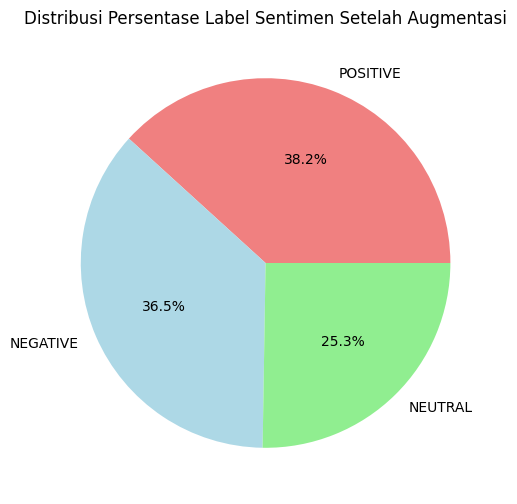

In [ ]:
import matplotlib.pyplot as plt

# Hitung jumlah label
label_counts = df_final['sent_label'].value_counts()
label_percent = (label_counts / label_counts.sum()) * 100

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(label_percent, labels=label_percent.index, autopct='%1.1f%%', colors=['lightcoral', 'lightblue', 'lightgreen'])
plt.title('Distribusi Persentase Label Sentimen Setelah Augmentasi')
plt.show()

In [ ]:
print(df_final['sent_label'].unique())


['NEGATIVE' 'NEUTRAL' 'POSITIVE']


In [ ]:
df_final.columns

Index(['created_at', 'username', 'full_text', 'cleaning', 'case_folding',
       'normalisasi', 'tokenize', 'stopword removal', 'stemming_data',
       'sent_label', 'sent_score'],
      dtype='object')

In [ ]:
!pip install transformers torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 55.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 84.8 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

# Load model IndoBERT Sentiment Analysis
model_name = "crypter70/IndoBERT-Sentiment-Analysis"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Buat pipeline untuk analisis sentimen
sentiment_pipe = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

Device set to use cpu


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


# Encode label (pastikan kolom label bernama 'sent_label')
label_encoder = LabelEncoder()
df_final['encoded_label'] = label_encoder.fit_transform(df_final['sent_label'])

In [ ]:
# Membersihkan kolom 'cleaning' dari NaN atau baris kosong
df_final = df_final[df_final['stemming_data'].notna()]
df_final = df_final[df_final['stemming_data'].str.strip() != '']
df_final.loc[:, 'stemming_data'] = df_final['stemming_data'].astype(str)
df_final = df_final.reset_index(drop=True)

In [ ]:
df_final['stemming_data'] = df_final['stemming_data'].fillna('').astype(str)

In [ ]:
#tokenizing

# Tokenisasi teks
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(df_final['stemming_data'])

sequences = tokenizer.texts_to_sequences(df_final['stemming_data'])

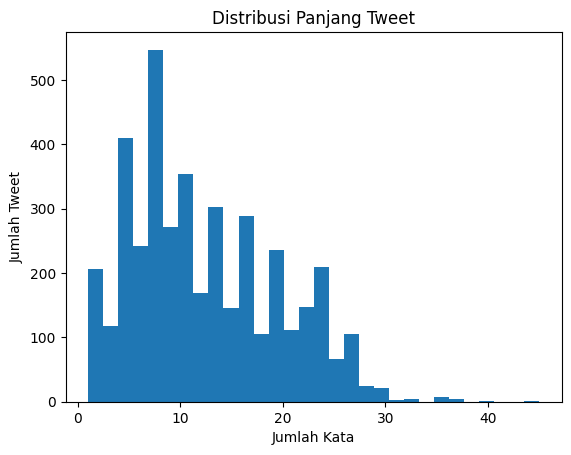

In [ ]:
import matplotlib.pyplot as plt

# Hitung panjang setiap tweet
tweet_lengths = [len(tweet.split()) for tweet in df_final['stemming_data']]

# Visualisasikan distribusinya
plt.hist(tweet_lengths, bins=30)
plt.title('Distribusi Panjang Tweet')
plt.xlabel('Jumlah Kata')
plt.ylabel('Jumlah Tweet')
plt.show()

In [ ]:
# Padding
max_len = 50  #  distribusi panjang teks
padded_sequences = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

In [ ]:
from tensorflow.keras.utils import to_categorical

# One-hot encoding untuk label
onehot_labels = to_categorical(df_final['encoded_label'], num_classes=3)

# 0 → [1. 0. 0.]
# 1 → [0. 1. 0.]
# 2 → [0. 0. 1.]

In [ ]:
df.head(5)

,created_at,username,full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal,stemming_data,sent_label,sent_score
0,Fri Dec 27 22:21:19 +0000 2024,PanitiaMbg,@opposite6892 Orang gila 300 T ruginya,Orang gila T ruginya,orang gila t ruginya,orang gila t ruginya,"['orang', 'gila', 't', 'ruginya']","['orang', 'gila', 't', 'ruginya']",orang gila t rugi,NEGATIVE,0.999951
1,Fri Dec 27 22:14:23 +0000 2024,PanitiaMbg,@zakariamlk nanti juga kalau mau minjem lagi p...,nanti juga kalau mau minjem lagi paling diunb...,nanti juga kalau mau minjem lagi paling diunb...,nanti juga kalau mau minjem lagi paling diunblock,"['nanti', 'juga', 'kalau', 'mau', 'minjem', 'l...","['minjem', 'diunblock']",minjem diunblock,NEUTRAL,0.999511
2,Fri Dec 27 17:49:09 +0000 2024,PanitiaMbg,@nonerahm @ruangtaktik @bliblidotcom nahini le...,nahini lebih manuk akal,nahini lebih manuk akal,nahini lebih masuk akal,"['nahini', 'lebih', 'masuk', 'akal']","['nahini', 'masuk', 'akal']",nahini masuk akal,POSITIVE,0.999953
3,Fri Dec 27 15:21:39 +0000 2024,ZoneVenomWar,Warga x yang ga napak tanah bingung lihat ini....,Warga x yang ga napak tanah bingung lihat ini ...,warga x yang ga napak tanah bingung lihat ini ...,warga kali yang tidak napak tanah bingung liha...,"['warga', 'kali', 'yang', 'tidak', 'napak', 't...","['warga', 'kali', 'tidak', 'napak', 'tanah', '...",warga kali tidak napak tanah bingung lihat ber...,NEGATIVE,0.999727
4,Fri Dec 27 15:04:34 +0000 2024,aanacessary,hidup lagi capek capeknya jaket vintage ku dic...,hidup lagi capek capeknya jaket vintage ku dic...,hidup lagi capek capeknya jaket vintage ku dic...,hidup lagi capek capeknya jaket vintage ku dic...,"['hidup', 'lagi', 'capek', 'capeknya', 'jaket'...","['hidup', 'capek', 'capeknya', 'jaket', 'vinta...",hidup capek capek jaket vintage ku colong oran...,NEGATIVE,0.999936


In [ ]:
#split data (test set & training set)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    padded_sequences, onehot_labels,
    test_size=0.2,
    random_state=42
)

In [ ]:
#visualisasi split data
print("Shape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test:", y_test.shape)

Shape X_train: (3280, 50)
Shape X_test: (821, 50)
Shape y_train: (3280, 3)
Shape y_test: (821, 3)


In [ ]:
print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 3280
Jumlah data testing: 821


In [ ]:
import numpy as np
import pandas as pd

# Kembalikan dari one-hot ke angka kelas
train_labels = np.argmax(y_train, axis=1)
test_labels = np.argmax(y_test, axis=1)

label_map = {0: 'NEGATIVE', 1: 'NEUTRAL', 2: 'POSITIVE'}

train_labels_named = pd.Series(train_labels).map(label_map)
test_labels_named = pd.Series(test_labels).map(label_map)

print("Distribusi sentimen (train):")
print(train_labels_named.value_counts())

print("\nDistribusi sentimen (test):")
print(test_labels_named.value_counts())

Distribusi sentimen (train):
POSITIVE    1283
NEGATIVE    1165
NEUTRAL      832
Name: count, dtype: int64

Distribusi sentimen (test):
NEGATIVE    335
POSITIVE    280
NEUTRAL     206
Name: count, dtype: int64


In [ ]:
#SMOTE

from imblearn.over_sampling import SMOTE
from tensorflow.keras.utils import to_categorical
import numpy as np

# 1. Ubah label dari one-hot ke label integer dulu
y_train_labels = np.argmax(y_train, axis=1)

# 2. Terapkan SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled_labels = smote.fit_resample(X_train, y_train_labels)

# 3. Kembalikan hasil SMOTE ke one-hot encoding
y_train_resampled = to_categorical(y_train_resampled_labels, num_classes=3)

# 4. Cek hasil
print("Shape X_train_resampled:", X_train_resampled.shape)
print("Shape y_train_resampled:", y_train_resampled.shape)

Shape X_train_resampled: (3849, 50)
Shape y_train_resampled: (3849, 3)


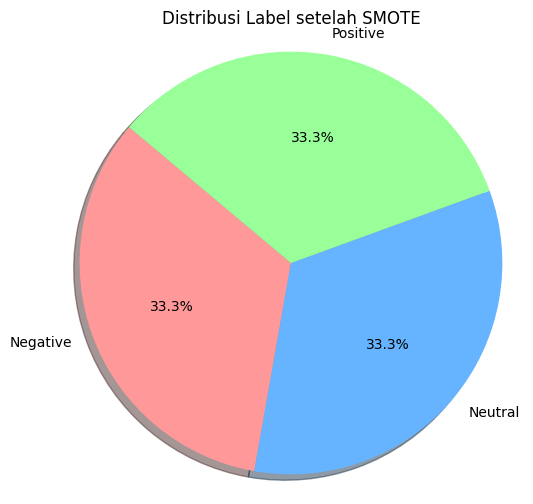

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Ambil label hasil SMOTE (dari one-hot ke label)
resampled_labels = np.argmax(y_train_resampled, axis=1)

# Hitung jumlah per label
unique, counts = np.unique(resampled_labels, return_counts=True)
label_names = ['Negative', 'Neutral', 'Positive']
colors = ['#ff9999', '#66b3ff', '#99ff99']

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=label_names, autopct='%1.1f%%', colors=colors, startangle=140, shadow=True)
plt.title('Distribusi Label setelah SMOTE')
plt.axis('equal')
plt.show()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 54s 456ms/step - accuracy: 0.3454 - loss: 1.7091 - val_accuracy: 0.4117 - val_loss: 1.5129 - learning_rate: 1.0000e-04
Epoch 2/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 24s 398ms/step - accuracy: 0.3954 - loss: 1.5812 - val_accuracy: 0.5481 - val_loss: 1.4958 - learning_rate: 1.0000e-04
Epoch 3/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 42s 419ms/step - accuracy: 0.4540 - loss: 1.4742 - val_accuracy: 0.6614 - val_loss: 1.4705 - learning_rate: 1.0000e-04
Epoch 4/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 39s 391ms/step - accuracy: 0.5156 - loss: 1.3824 - val_accuracy: 0.6955 - val_loss: 1.4335 - learning_rate: 1.0000e-04
Epoch 5/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 42s 407ms/step - accuracy: 0.5706 - loss: 1.2998 - val_accuracy: 0.7101 - val_loss: 1.3844 - learning_rate: 1.0000e-04
Epoch 6/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 25s 417ms/step - accuracy: 0.6283 - loss: 1.1966 - val_accuracy: 0.7576 - val_loss: 1.3146 - learning_rate: 1.0000e-04
Epoch 7/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 40s 406ms/step - acc

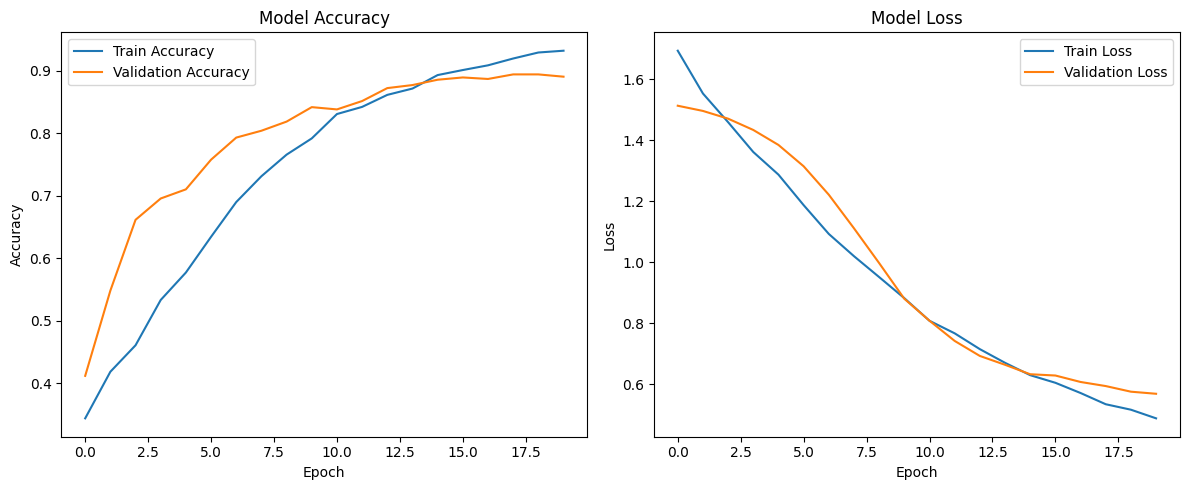

In [ ]:
#LSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import regularizers
from tensorflow.keras.layers import SpatialDropout1D

# Arsitektur model yang diperbaiki
model = Sequential()
model.add(Embedding(input_dim=10000, output_dim=128, input_length=200)) #embedding layer
model.add(SpatialDropout1D(0.2))

# Stacked Bidirectional LSTM
model.add(Bidirectional(LSTM(64, return_sequences=True, dropout=0.3, recurrent_dropout=0.2)))
model.add(Bidirectional(LSTM(32, return_sequences=False, dropout=0.3, recurrent_dropout=0.2)))
model.add(BatchNormalization())

# Dense layer
model.add(Dense(32, activation='tanh', kernel_regularizer=regularizers.l2(0.01)))
model.add(Dropout(0.4))

# Output layer
model.add(Dense(3, activation='softmax'))  # 3 kelas: negatif, netral, positif

# Compile
model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=1e-4),
    metrics=['accuracy']
)

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)

# Train model
history = model.fit(
    X_train_resampled, y_train_resampled,
    epochs=20,
    batch_size=64,
    validation_data=(X_test, y_test),
    callbacks=[early_stop, reduce_lr]
)

# Visualisasi hasil
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
#data testing

# Evaluasi ke data test
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.5695
Test Accuracy: 0.8904


26/26 ━━━━━━━━━━━━━━━━━━━━ 17s 466ms/step
              precision    recall  f1-score   support

    Negative       0.93      0.93      0.93       335
     Neutral       0.87      0.76      0.81       206
    Positive       0.86      0.93      0.90       280

    accuracy                           0.89       821
   macro avg       0.89      0.88      0.88       821
weighted avg       0.89      0.89      0.89       821



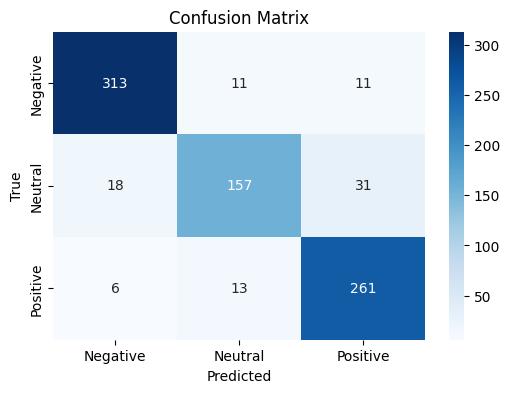

In [ ]:
#confusion matrix
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Prediksi label
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

# Laporan klasifikasi
print(classification_report(y_true, y_pred, target_names=['Negative', 'Neutral', 'Positive']))

# Confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Neutral', 'Positive'],
            yticklabels=['Negative', 'Neutral', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()